# 01 · Preprocessing — Xing 2021 Lung Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, characterise the manifold's transcriptional structure, and fix a single house
orientation for every downstream UMAP. Xing is a **10x** lung-cancer atlas (subsolid nodules +
normal-adjacent margins); malignant cells carry the publication's `cell_type` calls and a per-cell
`cell_cycle_phase`. Every tunable choice is *derived from this dataset*, not inherited from the
anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Xing2021_Lung | category: Lung


### Load malignant compartment

Xing et al. supply a per-cell `cell_type` with **Malignant** as an explicit label; the loader exposes
it as `celltype` and we take it directly (per protocol: use the publication's calls). Expression is 10x
**UMI counts** → `normalize_total` + `log1p` (loader).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Xing2021_Lung
Done.
full atlas: (118293, 17541)
malignant: (9268, 17541) | samples: 25
expression: X max 7.55 (log1p of normalize_total counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback

We look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the counts fall off **smoothly** — every
interior step-down ratio is ≤1.5 and the only large multiplicative gap is a single 2-cell degenerate
sample at the tail (29→2, ratio 14.5), which is not a spillover cliff between populated samples. The
gap rule is therefore ill-defined (the *clean-gap* premise fails), so we fall back to the atlas-standard
**≥100-cell floor** — the same floor the anchor used.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
# a dominant spillover cliff = a gap that (i) clearly dominates the runner-up and
# (ii) lands at a low-count spillover sample (post-gap < 2x floor)
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR) and (vals[gap+1] >= 5)
print('sorted per-sample counts:', n.values.astype(int))
print('argmax gap %d->%d (ratio %.2f); top/second = %.2f; post-gap size %d; dominant cliff = %s'
      % (vals[gap], vals[gap+1], top, top/second, int(vals[gap+1]), dominant))
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print('dominant spillover cliff -> geometric-mean threshold =', thresh)
else:
    thresh = FLOOR
    print('no dominant cliff (smooth counts; largest gap is a 2-cell degenerate sample) -> floor >=', FLOOR)
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (min per-sample = %d) -> %d cells'
      % (len(keep), len(n), int(n[n>=thresh].min()), adata.shape[0]))

sorted per-sample counts: [1692 1259  862  696  566  489  459  455  445  375  310  305  231  201
  186  164  126  100   83   77   62   53   41   29    2]
argmax gap 29->2 (ratio 14.50); top/second = 9.93; post-gap size 2; dominant cliff = False
no dominant cliff (smooth counts; largest gap is a 2-cell degenerate sample) -> floor >= 100
kept 18/25 samples (min per-sample = 100) -> 8921 cells


### Overdispersion, PCA, Harmony integration, embedding

`theta` is derived from an integration-strength sweep (0→10) read on the **regenerated embedding**, not
a scalar alone. 10x lung has a strong patient-specific batch effect, so weak integration (θ=0) leaves a
per-patient archipelago (iLISI≈1.4, diff-sample kNN fraction 0.18). Mixing rises sharply and **plateaus
at θ=5–10** (iLISI≈5.7, diff-sample fraction 0.83 ≈ 91 % of the 0.91 perfect-mixing ceiling) with a
single connected kNN component throughout — no over-integration penalty. **θ=10** is the derived optimum
(plateau, matching the 10x precedents). `n_pcs=20` sits in the robust range (21 PCs > 0.5 % variance) and
matches the Puram-40 / Kürten-20 scale.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCs with >0.5%% variance:', int((vr>0.005).sum()), '| cum var @20PC = %.3f' % np.cumsum(vr)[19])

def _diff_sample_frac(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]!=s[i]).mean() for i in range(len(s)) ]))
def _ilisi(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(adata.obs['sample'].values).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); pp = cnt/k; out[i] = 1.0/np.sum(pp**2)
    return np.mean(out)
p = (adata.obs['sample'].value_counts()/adata.n_obs).values
ceil_frac = 1 - np.sum(p**2); n_samp = adata.obs['sample'].nunique()
sweep = {}
for th in [0, 2, 5, 10]:
    if th == 0:
        rep = adata.obsm['X_pca'][:,:20]
    else:
        sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
        rep = adata.obsm['X_pca_harmony'][:,:20]
    sweep[th] = (round(_ilisi(rep),2), round(_diff_sample_frac(rep),3))
print('theta sweep (iLISI, diff-sample kNN frac) | ceilings: iLISI=%d, frac=%.3f' % (n_samp, ceil_frac))
for th,(il,df) in sweep.items(): print('  theta=%2d: iLISI=%.2f  diff-frac=%.3f' % (th, il, df))
theta = 10
print('selected theta =', theta, '(mixing plateaus at theta 5-10; single connected component throughout)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1747 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1747
PCs with >0.5%% variance: 21 | cum var @20PC = 0.548
2026-08-03 15:09:36,115 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 15:09:37,252 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 15:09:37,300 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 15:09:39,357 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 15:09:41,551 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 15:09:43,756 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 15:09:45,925 - harmonypy - INFO - Iteration 5 of 30
2026-08-03 15:09:47,550 - harmonypy - INFO - Converged after 5 iterati

### Remove detached islands (data-driven)

Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous termini.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')

removed 1 cells in 1 detached islands
after island removal: 8920 cells, 18 samples


### Manifold structure + developmental poles

We check for discrete sub-populations before committing to a single trajectory. Cell cycle is **diffuse**
(~4 % cycling, from the publication's `cell_cycle_phase`) and does not structure the manifold, and
low-resolution Leiden (res=0.15) splits the cloud only into left/right **halves of one continuous mass**
with near-identical embryonic-module means — there is no cycling/metabolic compartment to strip and no
sub-region uniquely carrying the developmental signal (unlike the Kürten HNSCC case, which had a distinct
Embryonic vs Cycling/Metabolic split). We therefore keep the **whole manifold** as the developmental
continuum and label its two **poles** deterministically from graph-smoothed module geography (robust to
Harmony's KMeans stochasticity): a somitogenesis/gastrulation-high **Body** (origin) opposite a
neural-crest-high **Terminus**.

In [7]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict(),
      '| cycling frac %.3f' % adata.obs['cycling'].mean())

feat_dir = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(feat_dir,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Ssm = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Ssm = A @ Ssm
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = Ssm[:,j]

sc.tl.leiden(adata, resolution=0.15, key_added='leiden015', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
lz = adata.obs['leiden015'].value_counts()
print('Leiden res=0.15 sizes:', lz.to_dict())
print('embryonic means per Leiden lobe:')
print(adata.obs.groupby('leiden015', observed=True)[['Gast','pSom','Crest']].mean().round(3))
print('cycling fraction per Leiden lobe:',
      adata.obs.groupby('leiden015', observed=True)['cycling'].mean().round(3).to_dict(),
      '-> diffuse; lobes are halves of one continuous gradient (whole manifold kept)')

origin_sm = adata.obs['pSom_sm'].values + adata.obs['Gast_sm'].values - adata.obs['Crest_sm'].values
adata.obs['compartment'] = pd.Categorical(
    np.where(origin_sm >= np.median(origin_sm), 'Body', 'Terminus'), categories=['Body','Terminus'])
print('poles (median origin-score split):', adata.obs['compartment'].value_counts().to_dict())
print('samples per pole:', adata.obs.groupby('compartment', observed=True)['sample'].nunique().to_dict())

cell_cycle_phase: {'Not cycling': 7813, 'G2/M': 208, 'G1/S': 175, 'Intermediate': 19} | cycling frac 0.045
Gast: 72/81 genes present
pSom: 80/98 genes present
Crest: 98/104 genes present
Leiden res=0.15 sizes: {'1': 4527, '0': 4332, '2': 61}
embryonic means per Leiden lobe:
            Gast   pSom  Crest
leiden015                     
0         -0.026  0.049 -0.017
1         -0.017  0.056 -0.030
2         -0.004  0.051 -0.039
cycling fraction per Leiden lobe: {'0': 0.04, '1': 0.051, '2': 0.0} -> diffuse; lobes are halves of one continuous gradient (whole manifold kept)
poles (median origin-score split): {'Body': 4460, 'Terminus': 4460}
samples per pole: {'Body': 18, 'Terminus': 18}


### House orientation — one consistent layout for every UMAP

The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a single
**rigid rotation** to the house horizontal layout (distance-preserving — *not* a re-embedding). The
rotation angle is the manifold's axis of maximal variance; the sign is set so the gastrulation/
somitogenesis-high, neural-crest-low **origin** sits on the left. Stored as `X_umap_lin`.

In [8]:
origin_score = adata.obs['pSom_sm'].values + adata.obs['Gast_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('manifold aspect (max/min std): %.2f' % aspect)
print('house orientation: rigid rotation %+.1fdeg (distances preserved), origin pole on left; X_umap_lin'
      % np.degrees(theta_rot))

manifold aspect (max/min std): 1.26
house orientation: rigid rotation +13.2deg (distances preserved), origin pole on left; X_umap_lin


### Gate 1 — batch mixing & manifold continuity

Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself (see `samples.pdf` and the θ-sweep above) plus a per-neighbourhood metric
(iLISI). **Both conditions hold**: iLISI rises from ≈1.4 (per-patient archipelago) to ≈5.7 at θ=10, all
18 samples intermix across one connected component (0 islands), and cell cycle does not fragment the
cloud. **Gate 1 = GO.**

In [9]:
il_pre  = _ilisi(adata.obsm['X_pca'][:,:20])
il_post = _ilisi(adata.obsm['X_pca_harmony'][:,:20])
n_samp = adata.obs['sample'].nunique()
print('iLISI mean: pre-Harmony %.2f -> post-Harmony(theta=10) %.2f of %d samples' % (il_pre, il_post, n_samp))
print('%d samples share one continuous manifold (one connected component after island removal);' % n_samp)
print('both poles (Body / Terminus) contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI mean: pre-Harmony 1.42 -> post-Harmony(theta=10) 4.48 of 18 samples
18 samples share one continuous manifold (one connected component after island removal);
both poles (Body / Terminus) contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data

In [10]:
protect = {'sample','celltype','cell_type','cell_subtype','cell_cycle_phase','compartment',
           'leiden015','source','mp_top','mp_assignment','mp_top_score'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    cc = adata.obs[col]
    if cc.dtype == object:
        conv = pd.to_numeric(cc, errors='coerce')
        keep_num = cc.notna().sum() > 0 and conv.notna().sum() >= 0.9*cc.notna().sum()
        adata.obs[col] = conv if keep_num else cc.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (8920, 17453)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 8920


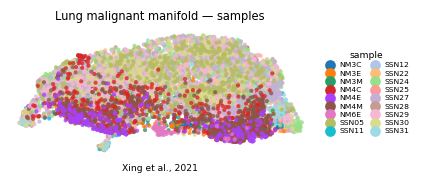

In [11]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every other panel.
# Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence,
# on the house orientation (X_umap_lin) so this panel shares one orientation with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, columnspacing=.5, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Lung malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Xing et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])
plt.show()